# 10.3. Когортная окупаемость

Аналитика 101 · блок «Дата аналитика» · тема 10 «Юнит-экономика» · страница 10.3.

По данным учебного магазина проверим, как изменения удержания, среднего чека и расходов на рекламу сказываются на окупаемости. Затем сравним стоимость привлечения с годовым доходом на клиента для трёх каналов. В соседнем файле `payback.sql` окупаемость каналов и когорт рассчитана в PostgreSQL.

Выполняйте ячейки сверху вниз. Для построения графика понадобятся результаты предыдущих расчётов.

Вывод получен на Python 3.13, pandas 3.0, NumPy 2.5 и matplotlib 3.10.

## Где лежат данные

Распакуйте архив главы так, чтобы папка `data/` находилась рядом с папкой урока. В `data/unit/` должны лежать `clients.csv`, `orders.csv` и `marketing_spend.csv`. Первая ячейка найдёт папку с материалами и сделает её рабочей. В ней появится график `payback_limits.svg`.

In [1]:
import os
import pathlib
import platform

import matplotlib
import numpy as np
import pandas as pd

root = pathlib.Path.cwd()
while not (root / "data" / "unit").is_dir() and root != root.parent:
    root = root.parent                      # поднимаемся, пока рядом не окажется data/unit/
assert (root / "data" / "unit" / "orders.csv").exists(), \
    "Не найдена папка data/unit/. Скачайте общий набор темы 10 и положите data/ рядом с папкой страницы"
os.chdir(root)

print("Python", platform.python_version(), "| pandas", pd.__version__, "| NumPy", np.__version__,
      "| matplotlib", matplotlib.__version__)

Python 3.13.18 | pandas 3.0.5 | NumPy 2.5.3 | matplotlib 3.10.0


## Сценарии расходов и окупаемости

Сначала оценим стоимость привлечения дополнительного клиента по эластичности, затем изменим удержание и средний чек. После этого пересчитаем результат эксперимента в рубли и построим денежный поток при росте расходов на привлечение.

### Что меняется при росте бюджета, удержания или среднего чека

In [2]:
import numpy as np
import pandas as pd

cl = pd.read_csv("data/unit/clients.csv", parse_dates=["signup_date"])
od = pd.read_csv("data/unit/orders.csv", parse_dates=["order_date"])
sp = pd.read_csv("data/unit/marketing_spend.csv")
od["margin"] = np.where(od["refunded"] == 1, -2 * od["delivery_cost"] - od["payment_fee"],
                        od["revenue"] - od["cogs"] - od["delivery_cost"] - od["payment_fee"])
month = lambda d: d.dt.year * 12 + d.dt.month          # сквозной номер месяца
LAST = 2026 * 12 + 6                                    # июнь 2026 — последний месяц данных
cl["m"] = month(cl["signup_date"])
od = od.merge(cl[["client_id", "channel", "m"]], on="client_id")
od["n"] = month(od["order_date"]) - od["m"]             # месяц жизни клиента, 0 — месяц регистрации

S = sp.pivot(index="month", columns="channel", values="spend")
N = pd.crosstab(cl["signup_date"].dt.strftime("%Y-%m"), cl["channel"])
CAC = S.sum() / N[S.columns].sum()


def increments(ch):
    """Доход за месяц n на клиента тех когорт, для которых этот месяц есть в данных."""
    size = cl[cl["channel"] == ch].groupby("m").size()
    margin = od[od["channel"] == ch].groupby("n")["margin"].sum()
    return np.array([margin.get(n, 0) / size[size.index + n <= LAST].sum() for n in range(24)])


# 1. Убывающая отдача: новые клиенты ∝ расходы^β, предельный CAC ≈ средний / β
beta = {ch: np.polyfit(np.log(S[ch]), np.log(N[ch]), 1)[0] for ch in ["поиск", "соцсети"]}
for ch, b in beta.items():
    print(f"{ch}: эластичность {b:.2f}, средний CAC {CAC[ch]:.0f} ₽, предельный ≈ {CAC[ch] / b:.0f} ₽")
dS, dN = S["соцсети"].diff()["2025-11"], N["соцсети"].diff()["2025-11"]
print(f"реклама в соцсетях, ноябрь 2025 года по сравнению с октябрём: +{dS / 1e6:.2f} млн ₽ и +{dN:.0f} клиентов, по {dS / dN:.0f} ₽ за каждого\n")

# 2. В сценариях для поиска удержание влияет на доход с месяца 1, изменение чека — с месяца 0
inc = increments("поиск")
o = od[od["channel"] == "поиск"]
M, DLV = o["margin"].mean(), o["delivery_cost"].mean()  # маржинальный доход и стоимость доставки на заказ


def scenario(ret=1.0, check=1.0, cac=CAC["поиск"]):
    k_check = (check * (M + DLV) - DLV) / M              # доставка не дешевеет вместе с чеком
    cum = (inc * np.r_[1.0, np.full(23, ret)] * k_check).cumsum()
    hit = np.flatnonzero(cum >= cac)
    return {"LTV 12": round(cum[11]), "LTV 24": round(cum[23]), "LTV 24/CAC": round(cum[23] / cac, 2),
            "окупаемость, n": hit[0] if len(hit) else "нет"}


table = pd.DataFrame.from_dict({"база": scenario(), "удержание +10%": scenario(ret=1.1), "чек −10%": scenario(check=0.9),
                                "удержание +10%, чек −10%": scenario(ret=1.1, check=0.9)}, orient="index")
print(table.to_string(), "\n")

# 3. Эффект эксперимента в деньгах: +2% к удержанию месяцев 1–11 у новичков года, горизонт 12 месяцев
year = cl[cl["signup_date"] >= "2025-07-01"]["channel"].value_counts()
gain = pd.Series({ch: year[ch] * 0.02 * increments(ch)[1:12].sum() for ch in year.index})
print(f"+2% к удержанию: поиск +{0.02 * inc[1:12].sum():.1f} ₽ на клиента, "
      f"для {year.sum()} новых клиентов всех каналов +{gain.sum() / 1e6:.2f} млн ₽ маржинального дохода за их первые 12 месяцев\n")


# 4. Бюджет на поиск растёт 12 месяцев, затем остаётся постоянным. Доход когорт учитываем до n = 23 включительно
def cash(growth, b, s0=1.2e6, months=36):
    s = s0 * (1 + growth) ** np.minimum(np.arange(months), 12)
    new = s0 / CAC["поиск"] * (s / s0) ** b                 # b = 1 — CAC не растёт с бюджетом
    cum = (np.convolve(new, inc)[:months] - s).cumsum()     # накопленный маржинальный доход всех когорт за вычетом расходов на привлечение
    up = [t for t in range(cum.argmin(), months) if cum[t] >= 0]
    return {"расходы с месяца 12, млн ₽": round(s[12] / 1e6, 2), "CAC новичков, ₽": round(s[12] / new[12]),
            "дно, млн ₽": round(cum.min() / 1e6, 1), "месяц дна": cum.argmin(), "в плюсе с месяца": up[0] if up else "нет"}


print(pd.DataFrame.from_dict({"без роста": cash(0, 1), "+10% в месяц, CAC постоянный": cash(0.10, 1),
                              "+10% в месяц, β = 0,78": cash(0.10, beta["поиск"])}, orient="index").to_string())

поиск: эластичность 0.78, средний CAC 1506 ₽, предельный ≈ 1935 ₽
соцсети: эластичность 0.61, средний CAC 3054 ₽, предельный ≈ 5015 ₽
реклама в соцсетях, ноябрь 2025 года по сравнению с октябрём: +1.23 млн ₽ и +246 клиентов, по 5016 ₽ за каждого

                          LTV 12  LTV 24  LTV 24/CAC  окупаемость, n
база                        1482    2061        1.37              12
удержание +10%              1578    2215        1.47              10
чек −10%                    1300    1808        1.20              16
удержание +10%, чек −10%    1384    1943        1.29              14 

+2% к удержанию: поиск +19.2 ₽ на клиента, для 34514 новых клиентов всех каналов +0.61 млн ₽ маржинального дохода за их первые 12 месяцев

                              расходы с месяца 12, млн ₽  CAC новичков, ₽  дно, млн ₽  месяц дна в плюсе с месяца
без роста                                           1.20             1506        -4.2         11               26
+10% в месяц, CAC постоянный           

В модели рост удержания меняет доход с месяца 1. Месяц регистрации считается отдельно. Для каждой когорты в расчёт денежного потока входят её первые 24 месяца. Месяцы в последней таблице пронумерованы с нуля.

## Сравнение каналов привлечения

### Сравнение CAC с годовым доходом на клиента

In [3]:
import os

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

plt.rcParams.update({"svg.fonttype": "none", "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.spines.left": False})
ACCENT, DARK, GREY = "#c2417a", "#454f62", "#9aa3b2"
rows = ["соцсети", "поиск", "партнёры"]                         # снизу вверх: главный ряд — внизу, ближе к оси
limit = {ch: increments(ch)[:12].sum() for ch in rows}           # LTV 12 = предел CAC при окупаемости за год
rub = lambda v: f"{v:,.0f}".replace(",", " ") + " ₽"

fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
for y, ch in enumerate(rows):
    col = ACCENT if ch == "соцсети" else DARK                    # выделяем канал с наибольшим разрывом между CAC и годовым доходом
    lo, hi = sorted([limit[ch], CAC[ch]])
    ax.plot([lo, hi], [y, y], color=col, linewidth=2.5, alpha=0.35 if col == DARK else 0.6, solid_capstyle="butt")
    ax.scatter(limit[ch], y, s=70, facecolor="white", edgecolor=col, linewidth=2, zorder=3)
    ax.scatter(CAC[ch], y, s=70, color=col, zorder=3)
    for x, text in [(limit[ch], f"предел {rub(limit[ch])}"), (CAC[ch], f"платим {rub(CAC[ch])}")]:
        left = x == lo
        ax.annotate(text, (x, y), xytext=(-9 if left else 9, 0), textcoords="offset points",
                    ha="right" if left else "left", va="center", color=col, fontweight="bold" if col == ACCENT else None)
m = CAC["поиск"] / beta["поиск"]                                # предельный CAC: следующий клиент поиска
ax.plot([m, m], [0.78, 0.92], color=GREY, linewidth=1.5)
ax.annotate(f"предельный CAC в поиске ≈ {rub(m)}", (m, 0.78), xytext=(0, -3), textcoords="offset points",
            ha="left", va="top", color="#737c8f", fontsize=8.5)
ax.set(yticks=range(len(rows)), yticklabels=rows, xlim=(-650, 4300), ylim=(-0.55, 2.5))
ax.set_xticks([0, 1000, 2000, 3000, 4000], labels=[rub(v) for v in [0, 1000, 2000, 3000, 4000]])
ax.tick_params(axis="y", length=0, labelsize=11)
ax.grid(axis="x", color="#e8e8e8", linewidth=0.8)
ax.set_axisbelow(True)
fig.suptitle("Клиент из соцсетей обходится в 3 054 ₽ при доходе 449 ₽ за год", x=0.02, ha="left",
             fontweight="bold", fontsize=11.5)
ax.set_title("● Средний CAC      ○ Маржинальный доход на клиента за первые 12 месяцев",
             loc="left", fontsize=8, color="#737c8f")
ax.set_xlabel("Учебные данные магазина, июль 2024 — июнь 2026", loc="left", fontsize=7.5, color="#9aa3b2")
fig.savefig("payback_limits.svg")
print({ch: (round(CAC[ch]), round(limit[ch])) for ch in rows}, round(os.path.getsize("payback_limits.svg") / 1024, 1), "КБ")

{'соцсети': (3054, 449), 'поиск': (1506, 1482), 'партнёры': (1263, 1498)} 14.9 КБ


Перед запуском выполните предыдущую ячейку. Из неё понадобятся значения CAC, оценки эластичности и функция increments. График показан ниже.

Предыдущая ячейка сохранила график в `payback_limits.svg`. Выполните следующую ячейку, чтобы увидеть его здесь.

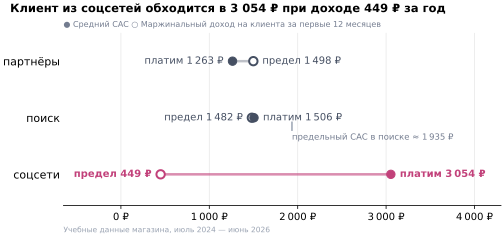

In [4]:
from IPython.display import SVG, display

display(SVG("payback_limits.svg"))